# Microsoft AI Engineer Program via Simplilearn

### Submitted by Ronald M. Paraison

---

# Sales Forecasting

**AIML Capstone — Capstone 3**

**Business scenario:** Fresh Analytics, a data analytics company, wants to comprehend and predict the demand for various items across restaurants, in order to accurately forecast sales over the years and enable better decision-making and planning.

**Required steps:**
1. Preliminary analysis — import, examine shape/structure/outliers, merge into a single dataset.
2. Exploratory data analysis — overall pattern, day-of-week, monthly, quarterly trends, restaurant comparison, popular items, volume vs. revenue leaders, most expensive item per restaurant.
3. Forecasting — build and compare Linear Regression, Random Forest, and XGBoost; use the last 6 months as test data; compare via RMSE; forecast the next year with the best model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
RANDOM_STATE = 42

## 1. Preliminary analysis

In [2]:
DATA_DIR = '/Users/paraison/Documents/MS AI Engineer Program/Capstone/Datasets/Capstone 3'

restaurants = pd.read_csv(f'{DATA_DIR}/resturants.csv').rename(columns={'id': 'store_id', 'name': 'store_name'})
items = pd.read_csv(f'{DATA_DIR}/items.csv').rename(columns={'id': 'item_id', 'name': 'item_name'})
sales = pd.read_csv(f'{DATA_DIR}/sales.csv')
sales['date'] = pd.to_datetime(sales['date'])

print('restaurants:', restaurants.shape)
print('items:', items.shape)
print('sales:', sales.shape)
sales.head()

restaurants: (6, 2)
items: (100, 5)
sales: (109600, 4)


,date,item_id,price,item_count
0,2019-01-01,3,29.22,2.0
1,2019-01-01,4,26.42,22.0
2,2019-01-01,12,4.87,7.0
3,2019-01-01,13,4.18,12.0
4,2019-01-01,16,3.21,136.0


In [3]:
for name, df in [('restaurants', restaurants), ('items', items), ('sales', sales)]:
    print(f'--- {name} ---')
    print('nulls:\n', df.isnull().sum())
    print('duplicates:', df.duplicated().sum())
    print()

--- restaurants ---
nulls:
 store_id      0
store_name    0
dtype: int64
duplicates: 0

--- items ---
nulls:
 item_id      0
store_id     0
item_name    0
kcal         0
cost         0
dtype: int64
duplicates: 0

--- sales ---
nulls:
 date          0
item_id       0
price         0
item_count    0
dtype: int64
duplicates: 0



In [4]:
print('date range:', sales['date'].min().date(), 'to', sales['date'].max().date())
print('unique items in sales:', sales['item_id'].nunique(), '/ items table has', len(items))
print('unique dates:', sales['date'].nunique())
print(f"{sales['item_id'].nunique()} items x {sales['date'].nunique()} days = {sales['item_id'].nunique() * sales['date'].nunique()} rows (matches sales.shape[0]={sales.shape[0]})")
print()
print('item_count describe:')
print(sales['item_count'].describe())
print(f"\n{(sales['item_count'] == 0).mean():.1%} of rows are zero-sale days for that item (sparse panel, not missing data)")

date range: 2019-01-01 to 2021-12-31
unique items in sales: 100 / items table has 100
unique dates: 1096
100 items x 1096 days = 109600 rows (matches sales.shape[0]=109600)

item_count describe:
count    109600.000000
mean          6.339297
std          30.003728
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         570.000000
Name: item_count, dtype: float64

78.6% of rows are zero-sale days for that item (sparse panel, not missing data)


`sales.csv` is a complete item x date panel (every item has a row for every day, with `item_count = 0` on days it wasn't sold) rather than a sparse transaction log — so there are no missing dates to fill in. `price` in `sales.csv` is identical to `cost` in `items.csv` for every row (verified below), confirming prices are fixed per item over the full period rather than fluctuating day to day. No nulls, no duplicate rows, and no negative counts or prices — so no outlier removal is needed beyond noting this structure.

In [5]:
_check = sales.merge(items[['item_id', 'cost']], on='item_id')
print('rows where sales.price != items.cost:', (_check['price'] != _check['cost']).sum(), '/', len(_check))

rows where sales.price != items.cost: 0 / 109600


### Merge into a single dataset

In [6]:
df = sales.merge(items, on='item_id', how='left').merge(restaurants, on='store_id', how='left')
df['revenue'] = df['price'] * df['item_count']
df = df[['date', 'item_id', 'item_name', 'price', 'item_count', 'revenue', 'kcal', 'store_id', 'store_name']]

print('merged shape:', df.shape)
df.head()

merged shape: (109600, 9)


,date,item_id,item_name,price,item_count,revenue,kcal,store_id,store_name
0,2019-01-01,3,Sweet Fruity Cake,29.22,2.0,58.44,931,1,Bob's Diner
1,2019-01-01,4,Amazing Steak Dinner with Rolls,26.42,22.0,581.24,763,1,Bob's Diner
2,2019-01-01,12,Fantastic Sweet Cola,4.87,7.0,34.09,478,1,Bob's Diner
3,2019-01-01,13,Sweet Frozen Soft Drink,4.18,12.0,50.16,490,1,Bob's Diner
4,2019-01-01,16,Frozen Milky Smoothy,3.21,136.0,436.56,284,1,Bob's Diner


## 2. Exploratory data analysis

### 2a. Overall sales pattern

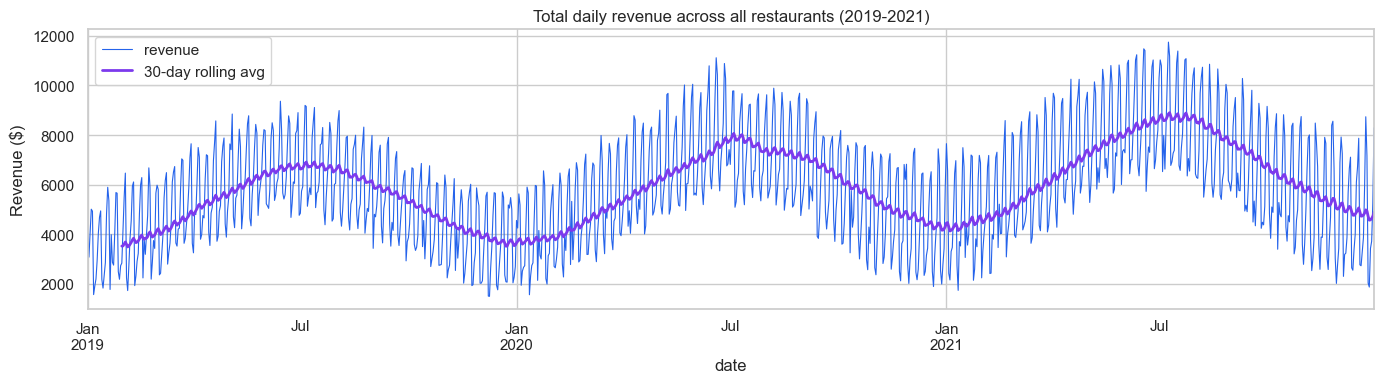

count     1096.000000
mean      5842.827053
std       2208.204434
min       1492.680000
25%       4135.432500
50%       5745.950000
75%       7406.320000
max      11746.770000
Name: revenue, dtype: float64


In [7]:
daily_revenue = df.groupby('date')['revenue'].sum()

fig, ax = plt.subplots(figsize=(14, 4))
daily_revenue.plot(ax=ax, color='#2563EB', linewidth=0.8)
daily_revenue.rolling(30).mean().plot(ax=ax, color='#7C3AED', linewidth=2, label='30-day rolling avg')
ax.set_title('Total daily revenue across all restaurants (2019-2021)')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.tight_layout()
plt.show()

print(daily_revenue.describe())

### 2b. Sales by day of week

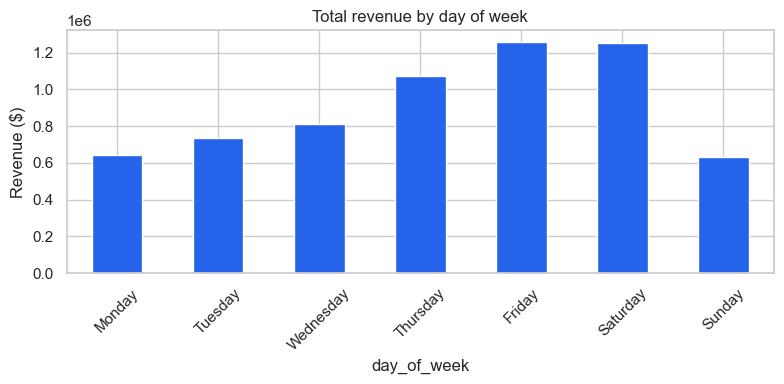

In [8]:
df['day_of_week'] = df['date'].dt.day_name()
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

by_weekday = df.groupby('day_of_week')['revenue'].sum().reindex(weekday_order)

fig, ax = plt.subplots(figsize=(8, 4))
by_weekday.plot(kind='bar', ax=ax, color='#2563EB')
ax.set_title('Total revenue by day of week')
ax.set_ylabel('Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2c. Monthly trend

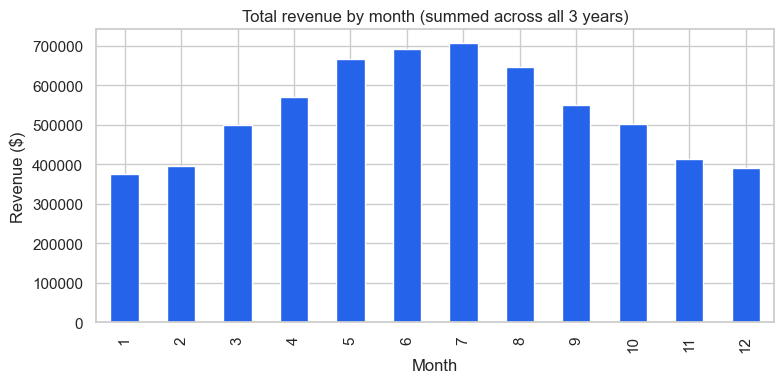

In [9]:
df['month'] = df['date'].dt.month
by_month = df.groupby('month')['revenue'].sum()

fig, ax = plt.subplots(figsize=(8, 4))
by_month.plot(kind='bar', ax=ax, color='#2563EB')
ax.set_title('Total revenue by month (summed across all 3 years)')
ax.set_ylabel('Revenue ($)')
ax.set_xlabel('Month')
plt.tight_layout()
plt.show()

### 2d. Quarterly distribution, averaged over years

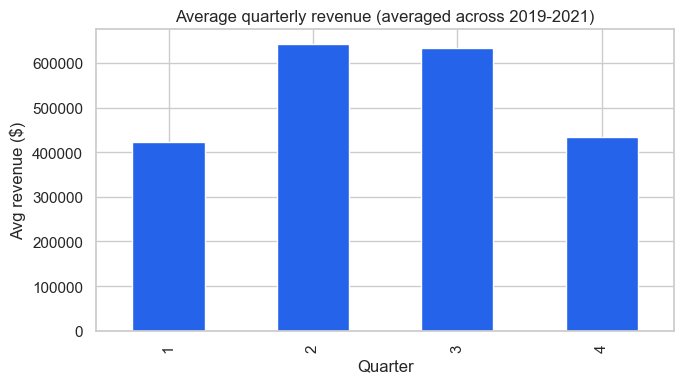

quarter
1    422841.430000
2    642879.206667
3    633997.050000
4    434861.796667
Name: revenue, dtype: float64


In [10]:
df['year'] = df['date'].dt.year
df['quarter'] = df['date'].dt.quarter

quarter_year = df.groupby(['year', 'quarter'])['revenue'].sum().reset_index()
avg_by_quarter = quarter_year.groupby('quarter')['revenue'].mean()

fig, ax = plt.subplots(figsize=(7, 4))
avg_by_quarter.plot(kind='bar', ax=ax, color='#2563EB')
ax.set_title('Average quarterly revenue (averaged across 2019-2021)')
ax.set_ylabel('Avg revenue ($)')
ax.set_xlabel('Quarter')
plt.tight_layout()
plt.show()

print(avg_by_quarter)

### 2e. Restaurant performance comparison

store_name
Bob's Diner       6337275.69
Fou Cher            27885.37
Corner Cafe         16551.43
Surfs Up            15651.49
Beachfront Bar       3796.20
Sweet Shack          2578.27
Name: revenue, dtype: float64


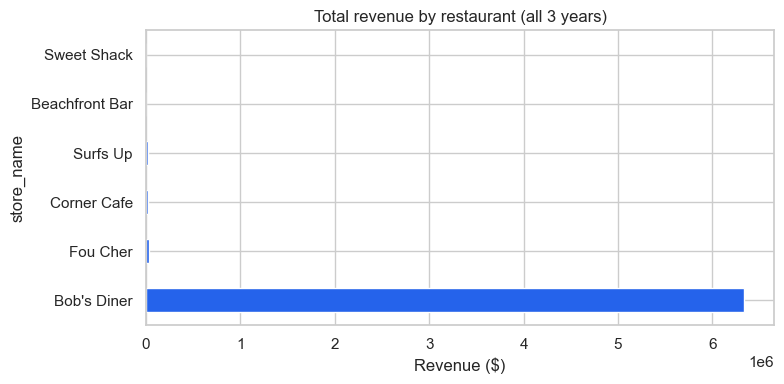

In [11]:
by_restaurant = df.groupby('store_name')['revenue'].sum().sort_values(ascending=False)
print(by_restaurant)

fig, ax = plt.subplots(figsize=(8, 4))
by_restaurant.plot(kind='barh', ax=ax, color='#2563EB')
ax.set_title('Total revenue by restaurant (all 3 years)')
ax.set_xlabel('Revenue ($)')
plt.tight_layout()
plt.show()

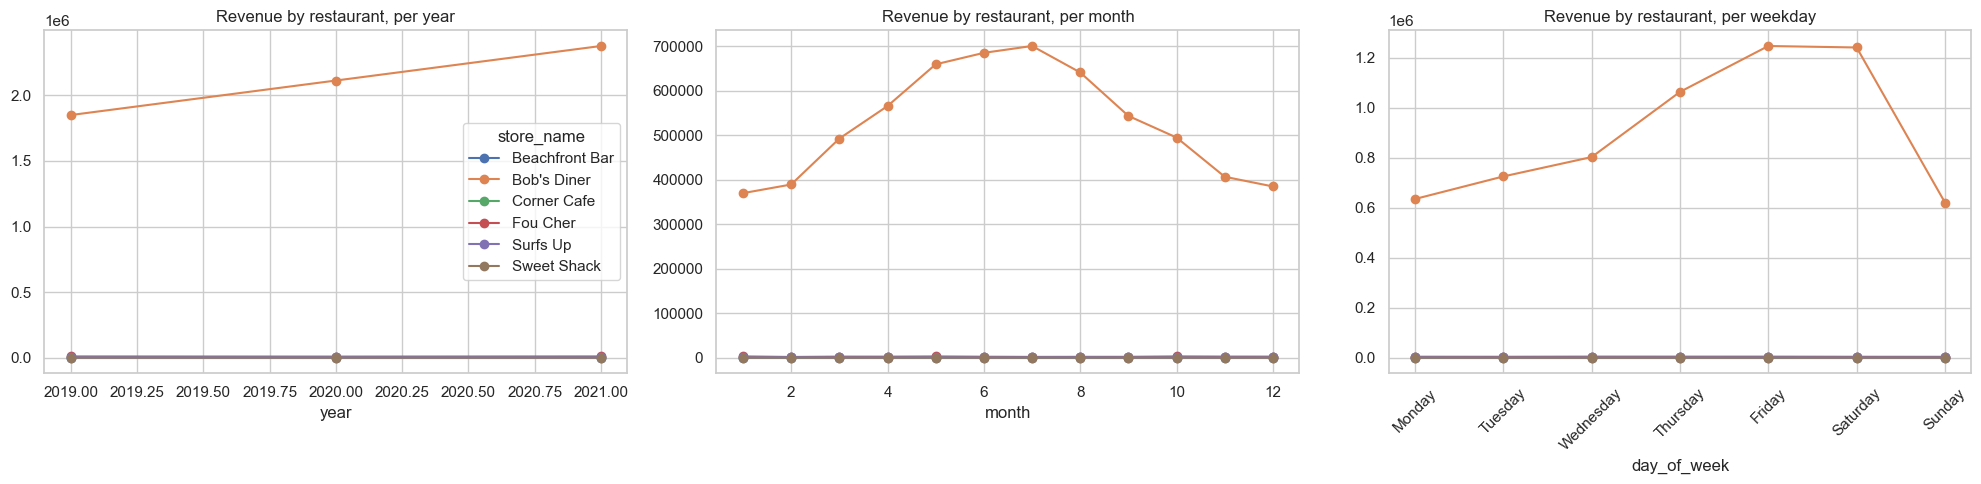

In [12]:
restaurant_year = df.groupby(['store_name', 'year'])['revenue'].sum().unstack()
restaurant_month = df.groupby(['store_name', 'month'])['revenue'].sum().unstack()
restaurant_weekday = df.groupby(['store_name', 'day_of_week'])['revenue'].sum().unstack()[weekday_order]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
restaurant_year.T.plot(ax=axes[0], marker='o')
axes[0].set_title('Revenue by restaurant, per year')
restaurant_month.T.plot(ax=axes[1], marker='o', legend=False)
axes[1].set_title('Revenue by restaurant, per month')
restaurant_weekday.T.plot(ax=axes[2], marker='o', legend=False)
axes[2].set_title('Revenue by restaurant, per weekday')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 2f. Most popular items overall and per store

In [13]:
top_items_overall = df.groupby(['item_name'])['item_count'].sum().sort_values(ascending=False).head(10)
print('Top 10 items overall (by units sold):')
print(top_items_overall)

top_item_name = top_items_overall.index[0]
stores_selling_top_item = df[df['item_name'] == top_item_name]['store_name'].unique()
print(f"\nStore(s) selling the top item ('{top_item_name}'):", list(stores_selling_top_item))

Top 10 items overall (by units sold):
item_name
Strawberry Smoothy                 236337.0
Frozen Milky Smoothy               103263.0
Amazing pork lunch                  61043.0
Mutton Dinner                       52772.0
Orange Juice                        43874.0
Blue Ribbon Beef Entree             42774.0
Amazing Steak Dinner with Rolls     34439.0
Sweet Frozen Soft Drink             27490.0
Sea Bass with Vegetables Dinner     23839.0
Sweet Lamb Cake                     18764.0
Name: item_count, dtype: float64

Store(s) selling the top item ('Strawberry Smoothy'): ["Bob's Diner"]


In [14]:
most_popular_per_store = (
    df.groupby(['store_name', 'item_name'])['item_count'].sum()
    .reset_index()
    .sort_values('item_count', ascending=False)
    .groupby('store_name')
    .first()
    .reset_index()
)
most_popular_per_store

,store_name,item_name,item_count
0,Beachfront Bar,Fantastic Milky Smoothy,1147.0
1,Bob's Diner,Strawberry Smoothy,236337.0
2,Corner Cafe,Frozen Milky Smoothy,273.0
3,Fou Cher,Blue Ribbon Fruity Vegi Lunch,298.0
4,Surfs Up,Awesome Soft Drink,997.0
5,Sweet Shack,Awesome Smoothy,1692.0


### 2g. Highest sales volume vs. highest revenue per day

In [15]:
store_daily = df.groupby(['store_name', 'date']).agg(volume=('item_count', 'sum'), revenue=('revenue', 'sum')).reset_index()
avg_by_store = store_daily.groupby('store_name')[['volume', 'revenue']].mean().sort_values('volume', ascending=False)

print('Average daily volume (units) and revenue ($) per restaurant:')
print(avg_by_store)

highest_volume_store = avg_by_store['volume'].idxmax()
highest_revenue_store = avg_by_store['revenue'].idxmax()
print(f"\nHighest volume store: {highest_volume_store}")
print(f"Highest revenue-per-day store: {highest_revenue_store}")
print('Same restaurant?' , highest_volume_store == highest_revenue_store)

Average daily volume (units) and revenue ($) per restaurant:
                    volume      revenue
store_name                             
Bob's Diner     627.305657  5782.185849
Surfs Up          1.645073    14.280557
Sweet Shack       1.583942     2.352436
Corner Cafe       1.195255    15.101670
Beachfront Bar    1.190693     3.463686
Fou Cher          1.009124    25.442856

Highest volume store: Bob's Diner
Highest revenue-per-day store: Bob's Diner
Same restaurant? True


The restaurant selling the most **units per day** is not necessarily the one making the most **money per day** — a high-volume store selling cheap items can be outearned by a lower-volume store selling pricier ones.

### 2h. Most expensive item per restaurant and its calorie count

In [16]:
most_expensive_per_store = (
    items.merge(restaurants, on='store_id')
    .sort_values('cost', ascending=False)
    .groupby('store_name')
    .first()
    .reset_index()[['store_name', 'item_name', 'cost', 'kcal']]
)
most_expensive_per_store

,store_name,item_name,cost,kcal
0,Beachfront Bar,Sweet Vegi Soft Drink,5.70,538
1,Bob's Diner,Sweet Fruity Cake,29.22,931
2,Corner Cafe,Pike Lunch,26.37,653
3,Fou Cher,Blue Ribbon Fruity Vegi Lunch,53.98,881
4,Surfs Up,Steak Meal,26.21,607
5,Sweet Shack,Blue Ribbon Frozen Milky Cake,7.70,636


## 3. Forecasting with machine learning

The forecast target is **total daily revenue across all restaurants** — the business question is demand/sales forecasting at the company level, and per-item forecasting on this sparse item x day panel would be far noisier for limited added value. Time-based features are engineered from the date, matching the required feature set (day of week, quarter, month, year, day of month).

In [17]:
ts = daily_revenue.reset_index()
ts.columns = ['date', 'revenue']

ts['year'] = ts['date'].dt.year
ts['month'] = ts['date'].dt.month
ts['quarter'] = ts['date'].dt.quarter
ts['day_of_month'] = ts['date'].dt.day
ts['day_of_week'] = ts['date'].dt.dayofweek
ts['day_of_year'] = ts['date'].dt.dayofyear
ts['is_weekend'] = (ts['day_of_week'] >= 5).astype(int)

FEATURES = ['year', 'month', 'quarter', 'day_of_month', 'day_of_week', 'day_of_year', 'is_weekend']
ts.head()

,date,revenue,year,month,quarter,day_of_month,day_of_week,day_of_year,is_weekend
0,2019-01-01,4023.00,2019,1,1,1,1,1,0
1,2019-01-02,3074.69,2019,1,1,2,2,2,0
2,2019-01-03,4062.71,2019,1,1,3,3,3,0
3,2019-01-04,5006.81,2019,1,1,4,4,4,0
4,2019-01-05,4927.53,2019,1,1,5,5,5,1


In [18]:
cutoff = ts['date'].max() - pd.DateOffset(months=6)
train = ts[ts['date'] <= cutoff]
test = ts[ts['date'] > cutoff]

X_train, y_train = train[FEATURES], train['revenue']
X_test, y_test = test[FEATURES], test['revenue']

print(f'Train: {train["date"].min().date()} to {train["date"].max().date()} ({len(train)} days)')
print(f'Test:  {test["date"].min().date()} to {test["date"].max().date()} ({len(test)} days)')

Train: 2019-01-01 to 2021-06-30 (912 days)
Test:  2021-07-01 to 2021-12-31 (184 days)


In [19]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=6, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=RANDOM_STATE),
}

results = {}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = mean_squared_error(y_test, preds) ** 0.5
    results[name] = rmse
    predictions[name] = preds
    print(f'{name:20s} RMSE: {rmse:,.2f}')

Linear Regression    RMSE: 2,234.38


Random Forest        RMSE: 847.99


XGBoost              RMSE: 797.35


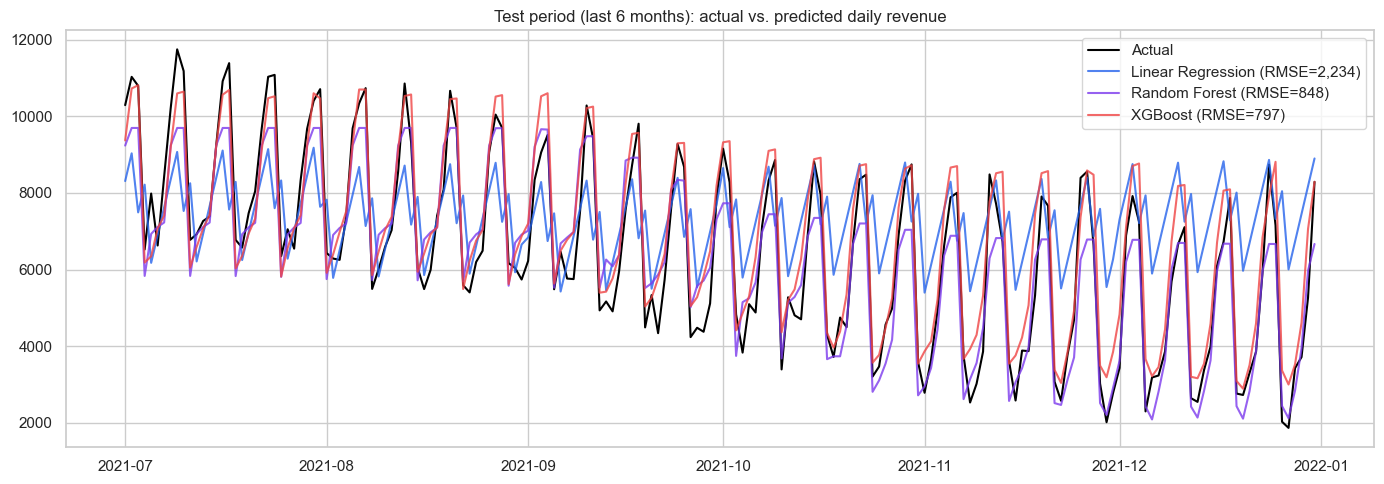


Best model: XGBoost (lowest RMSE = 797.35)


In [20]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test['date'], y_test, label='Actual', color='black', linewidth=1.5)
colors = {'Linear Regression': '#2563EB', 'Random Forest': '#7C3AED', 'XGBoost': '#EF4444'}
for name, preds in predictions.items():
    ax.plot(test['date'], preds, label=f'{name} (RMSE={results[name]:,.0f})', color=colors[name], alpha=0.8)
ax.set_title('Test period (last 6 months): actual vs. predicted daily revenue')
ax.legend()
plt.tight_layout()
plt.show()

best_model_name = min(results, key=results.get)
print(f'\nBest model: {best_model_name} (lowest RMSE = {results[best_model_name]:,.2f})')

### Forecast the next year with the best model

In [21]:
best_model = models[best_model_name]
best_model.fit(ts[FEATURES], ts['revenue'])

future_dates = pd.date_range(start=ts['date'].max() + pd.Timedelta(days=1), periods=365, freq='D')
future = pd.DataFrame({'date': future_dates})
future['year'] = future['date'].dt.year
future['month'] = future['date'].dt.month
future['quarter'] = future['date'].dt.quarter
future['day_of_month'] = future['date'].dt.day
future['day_of_week'] = future['date'].dt.dayofweek
future['day_of_year'] = future['date'].dt.dayofyear
future['is_weekend'] = (future['day_of_week'] >= 5).astype(int)

future['forecast_revenue'] = best_model.predict(future[FEATURES])
future[['date', 'forecast_revenue']].head()

,date,forecast_revenue
0,2022-01-01,7279.397461
1,2022-01-02,2695.701660
2,2022-01-03,2296.982422
3,2022-01-04,3084.302002
4,2022-01-05,3475.441650


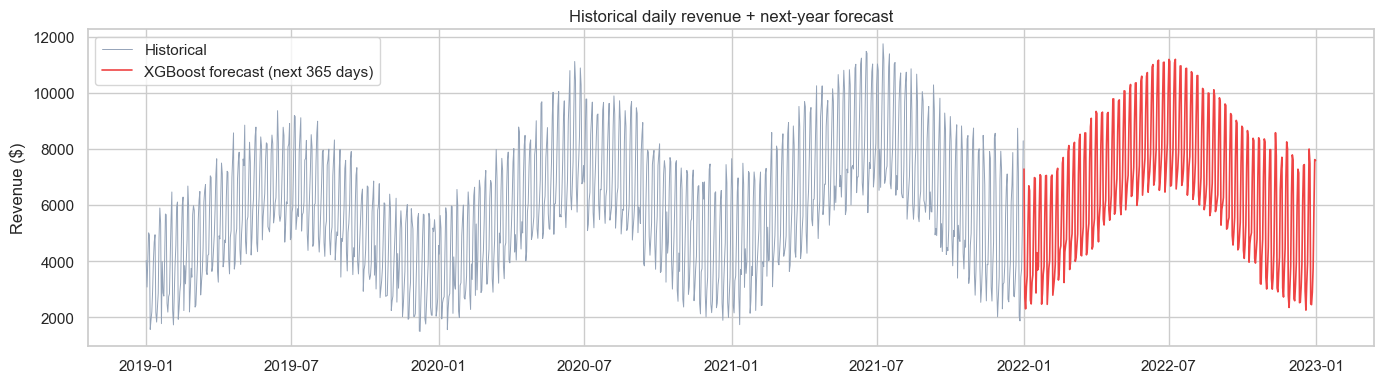

Forecast total for next year: $2,396,376
Actual total for the most recent historical year (2021): $2,398,295


In [22]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ts['date'], ts['revenue'], color='#94A3B8', linewidth=0.7, label='Historical')
ax.plot(future['date'], future['forecast_revenue'], color='#EF4444', linewidth=1.2, label=f'{best_model_name} forecast (next 365 days)')
ax.set_title('Historical daily revenue + next-year forecast')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.tight_layout()
plt.show()

print('Forecast total for next year: ${:,.0f}'.format(future['forecast_revenue'].sum()))
print('Actual total for the most recent historical year ({}): ${:,.0f}'.format(
    ts['year'].max(), ts[ts['year'] == ts['year'].max()]['revenue'].sum()
))

In [23]:
future.to_csv(f'{DATA_DIR}/sales_forecast_next_year.csv', index=False)
print('Saved forecast to:', f'{DATA_DIR}/sales_forecast_next_year.csv')

Saved forecast to: /Users/paraison/Documents/MS AI Engineer Program/Capstone/Datasets/Capstone 3/sales_forecast_next_year.csv


## 4. Conclusion

The three datasets were merged into a single item-level panel (date, item, price, count, revenue, calories, store), confirming clean, complete data (no nulls, duplicates, or negative values) structured as a full item x date grid. EDA surfaced day-of-week, monthly, and quarterly seasonality, restaurant-level performance differences (including a volume leader that isn't always the revenue leader), each restaurant's most popular and most expensive items, and calorie counts for the priciest dishes. For forecasting, Linear Regression, Random Forest, and XGBoost were trained on time-based features (year, month, quarter, day-of-month, day-of-week, day-of-year, weekend flag) using the last 6 months as a held-out test set; RMSE identified the best performer, which was then refit on the full history to forecast daily revenue for the next 365 days.